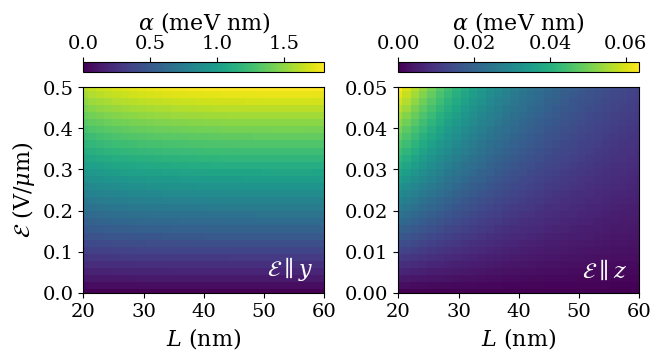

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
})

filenames = [
    "Pymablock_Y_kx0.001_emax_0.50_N100.dat",
    "Pymablock_Z_kx0.001_emax_0.05_N100.dat",
]

titles = [
    r"$\mathcal{E}\parallel y$",
    r"$\mathcal{E}\parallel z$",
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(6.5, 3.5),
    sharex=False,
    sharey=False,
    constrained_layout=True,
)

for ax, filename, title in zip(axes, filenames, titles):
    data = np.loadtxt(filename)

    L_values, L_index = np.unique(data[:, 0], return_inverse=True)
    E_values, E_index = np.unique(data[:, 1], return_inverse=True)

    alpha_grid = np.full((len(E_values), len(L_values)), np.nan)
    alpha_grid[E_index, L_index] = data[:, 2] * 100  # eV Å → meV nm

    # Each plot automatically uses its own alpha range
    pcm = ax.pcolormesh(
        L_values,
        E_values,
        alpha_grid,
        shading="auto",
        cmap="viridis",
    )

    ax.set_xlim(L_values.min(), L_values.max())
    ax.set_ylim(E_values.min(), E_values.max())

    ax.text(
        0.95, 0.05, title,
        transform=ax.transAxes,
        fontsize=16,
        color="white",
        ha="right",
        va="bottom",
    )
    ax.set_xlabel(r"$L$ (nm)", fontsize=16)
    if ax is axes[0]:
        ax.set_ylabel(r"$\mathcal{E}$ (V/$\mu$m)", fontsize=16)
    ax.tick_params(labelsize=14)

    cbar = fig.colorbar(
        pcm,
        ax=ax,
        location="top",
        orientation="horizontal",
        pad=0.04,
        fraction=0.08,
        aspect=25,
    )
    cbar.set_label(r"$\alpha$ (meV nm)", fontsize=16)
    cbar.ax.tick_params(labelsize=14)

fig.savefig("rashba_Y_Z_colorplot.png", dpi=300, bbox_inches="tight")
fig.savefig("rashba_Y_Z_colorplot.svg", dpi=300, bbox_inches="tight")
plt.show()

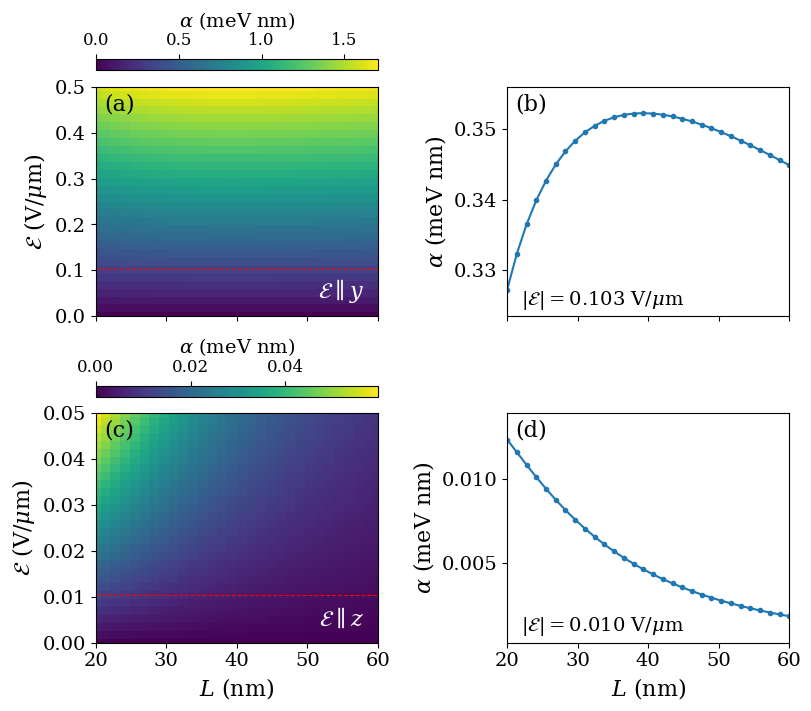

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
})

filenames = [
    "Pymablock_Y_kx0.001_emax_0.50_N50.dat",
    "Pymablock_Z_kx0.001_emax_0.05_N50.dat",
]

titles = [
    r"$\mathcal{E}\parallel y$",
    r"$\mathcal{E}\parallel z$",
]

L_range = (20, 60)
field_index = 6

fig, axes = plt.subplots(
    2, 2,
    figsize=(8, 7),
    sharex=True,
    sharey=False,
    constrained_layout=True,
)

line_data = []

for row, (filename, title) in enumerate(zip(filenames, titles)):
    ax_map = axes[row, 0]
    ax_line = axes[row, 1]

    data = np.loadtxt(filename)

    L_values, L_index = np.unique(data[:, 0], return_inverse=True)
    E_values, E_index = np.unique(data[:, 1], return_inverse=True)

    # Rows: E; columns: L
    alpha_grid = np.full((len(E_values), len(L_values)), np.nan)
    alpha_grid[E_index, L_index] = data[:, 2] * 100  # eV Å → meV nm

    # Each L block must contain the same E values in the same order
    step_L = len(E_values)

    if not 0 <= field_index < step_L:
        raise ValueError(f"{filename}: field_index must be below {step_L}")

    L_cut = data[field_index::step_L, 0]
    E_selected = data[field_index::step_L, 1]
    alpha_cut = data[field_index::step_L, 2] * 100

    # Check that the slicing selects one common E across all L values
    if (
        len(L_cut) != len(L_values)
        or not np.allclose(np.sort(L_cut), L_values)
        or not np.allclose(E_selected, E_selected[0])
    ):
        raise ValueError(
            f"{filename}: rows must be grouped by L with the same "
            "electric-field ordering in every block."
        )

    E_actual = E_selected[0]
    line_data.append((L_cut.copy(), alpha_cut.copy()))

    # Left: color map with independent color scale
    pcm = ax_map.pcolormesh(
        L_values,
        E_values,
        alpha_grid,
        shading="auto",
        cmap="viridis",
    )

    ax_map.set_ylim(E_values.min(), E_values.max())
    ax_map.axhline(
        E_actual, linestyle="--", color="red", linewidth=0.8
    )

    ax_map.text(
        0.95, 0.05, title,
        transform=ax_map.transAxes,
        fontsize=16,
        color="white",
        ha="right",
        va="bottom",
    )

    ax_map.set_ylabel(r"$\mathcal{E}$ (V/$\mu$m)", fontsize=16)

    # cbar = fig.colorbar(
    #     pcm,
    #     ax=ax_map,
    #     location="right",
    #     orientation="vertical",
    #     pad=0.03,
    #     fraction=0.06,
    #     aspect=20,
    # )
    cbar = fig.colorbar(
            pcm,
            ax=ax_map,
            location="top",
            orientation="horizontal",
            pad=0.04,
            fraction=0.08,
            aspect=25,
        )
    
    cbar.set_label(r"$\alpha$ (meV nm)", fontsize=14)
    cbar.ax.tick_params(labelsize=12)

    # Right: alpha versus L from positional slicing
    order = np.argsort(L_cut)
    ax_line.plot(
        L_cut[order],
        alpha_cut[order],
        "-o",
        color="tab:blue",
        linewidth=1.5,
        markersize=3,
    )

    ax_line.text(
        0.05, 0.12,
        rf"$|\mathcal{{E}}|={E_actual:.3f}$ V/$\mu$m",
        transform=ax_line.transAxes,
        fontsize=14,
        ha="left",
        va="top",
    )

    ax_line.set_ylabel(r"$\alpha$ (meV nm)", fontsize=16)
    # ax_line.grid(alpha=0.2)
    ax_line.margins(y=0.15)

    for ax in (ax_map, ax_line):
        ax.tick_params(labelsize=14)

# Panel labels in reading order
for i, (ax, label) in enumerate(
    zip(axes.flat, ["(a)", "(b)", "(c)", "(d)"])
):
    ax.text(
        0.03, 0.97, label,
        transform=ax.transAxes,
        fontsize=16,
        color="black" if i % 2 == 0 else "black",
        ha="left",
        va="top",
    )

# Shared x range; labels only on the bottom row
axes[1, 0].set_xlim(*L_range)

for ax in axes[1, :]:
    ax.set_xlabel(r"$L$ (nm)", fontsize=16)

for ax in axes[0, :]:
    ax.tick_params(axis="x", labelbottom=False)

L_y, alpha_list_y = line_data[0]
L_z, alpha_list_z = line_data[1]

fig.savefig("rashba_maps_and_cuts.png", dpi=300, bbox_inches="tight")
fig.savefig("rashba_maps_and_cuts.svg", bbox_inches="tight")
plt.show()

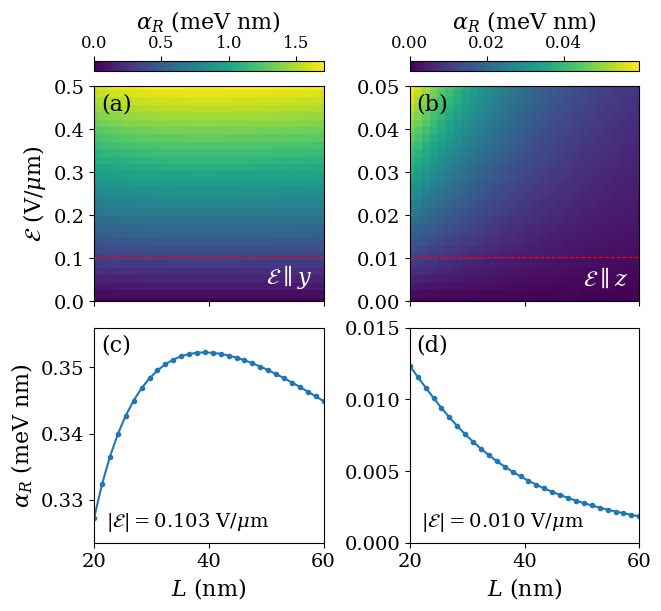

In [3]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
})

filenames = [
    "Pymablock_Y_kx0.001_emax_0.50_N50.dat",
    "Pymablock_Z_kx0.001_emax_0.05_N50.dat",
]

titles = [
    r"$\mathcal{E}\parallel y$",
    r"$\mathcal{E}\parallel z$",
]

field_index = 6  # Seventh element; use 5 for the sixth

fig, axes = plt.subplots(
    2, 2,
    figsize=(6.5, 6),
    sharex="col",
    sharey=False,
    constrained_layout=True,
)

line_data = []

for col, (filename, title) in enumerate(zip(filenames, titles)):
    ax_map = axes[0, col]
    ax_line = axes[1, col]

    data = np.loadtxt(filename)

    L_values, L_index = np.unique(data[:, 0], return_inverse=True)
    E_values, E_index = np.unique(data[:, 1], return_inverse=True)

    alpha_grid = np.full((len(E_values), len(L_values)), np.nan)
    alpha_grid[E_index, L_index] = data[:, 2] * 100  # eV Å → meV nm

    # Positional slicing within blocks grouped by L
    step_L = len(E_values)

    if not 0 <= field_index < step_L:
        raise ValueError(f"{filename}: field_index must be below {step_L}")

    L_cut = data[field_index::step_L, 0]
    E_selected = data[field_index::step_L, 1]
    alpha_cut = data[field_index::step_L, 2] * 100

    if (
        len(L_cut) != len(L_values)
        or not np.allclose(np.sort(L_cut), L_values)
        or not np.allclose(E_selected, E_selected[0])
    ):
        raise ValueError(
            f"{filename}: rows must be grouped by L with the same "
            "electric-field ordering in every block."
        )

    E_actual = E_selected[0]
    line_data.append((L_cut.copy(), alpha_cut.copy()))

    # Top row: color maps
    pcm = ax_map.pcolormesh(
        L_values,
        E_values,
        alpha_grid,
        shading="auto",
        cmap="viridis",
    )

    ax_map.set_xlim(L_values.min(), L_values.max())
    ax_map.set_ylim(E_values.min(), E_values.max())

    ax_map.axhline(
        E_actual, linestyle="--", color="red", linewidth=0.8
    )

    ax_map.text(
        0.95, 0.05, title,
        transform=ax_map.transAxes,
        fontsize=16,
        color="white",
        ha="right",
        va="bottom",
    )

    # Independent horizontal colorbar above each map
    cbar = fig.colorbar(
        pcm,
        ax=ax_map,
        location="top",
        orientation="horizontal",
        pad=0.04,
        fraction=0.08,
        aspect=25,
    )
    cbar.set_label(r"$\alpha_R$ (meV nm)", fontsize=16)
    cbar.ax.tick_params(labelsize=12)

    # Bottom row: alpha versus L
    order = np.argsort(L_cut)
    ax_line.plot(
        L_cut[order],
        alpha_cut[order],
        "-o",
        color="tab:blue",
        linewidth=1.5,
        markersize=3,
    )

    ax_line.text(
        0.05, 0.15,
        rf"$|\mathcal{{E}}|={E_actual:.3f}$ V/$\mu$m",
        transform=ax_line.transAxes,
        fontsize=14,
        ha="left",
        va="top",
    )

    ax_line.set_xlabel(r"$L$ (nm)", fontsize=16)
    # ax_line.grid(alpha=0.2)
    ax_line.margins(y=0.15)

    for ax in (ax_map, ax_line):
        ax.tick_params(labelsize=14)

# Y-axis labels on the left column
axes[0, 0].set_ylabel(r"$\mathcal{E}$ (V/$\mu$m)", fontsize=16)
axes[1, 0].set_ylabel(r"$\alpha_R$ (meV nm)", fontsize=16)
axes[1, 1].set_ylim(0,0.015)

# Panel labels in reading order
for i, (ax, label) in enumerate(
    zip(axes.flat, ["(a)", "(b)", "(c)", "(d)"])
):
    ax.text(
        0.03, 0.97, label,
        transform=ax.transAxes,
        fontsize=16,
        color="black" if i < 2 else "black",
        ha="left",
        va="top",
    )

# X tick labels only on the bottom row
for ax in axes[0, :]:
    ax.tick_params(axis="x", labelbottom=False)

L_y, alpha_list_y = line_data[0]
L_z, alpha_list_z = line_data[1]

fig.savefig("rashba_horizontal_maps_and_cuts.png",
            dpi=300, bbox_inches="tight")
fig.savefig("rashba_horizontal_maps_and_cuts.svg",
            bbox_inches="tight")
plt.show()